# 01 · Exploratory Data Analysis - Kodumudi (Cauvery) Catchment, 1980–2015

**Goal of this notebook:** understand the data before modelling it, i.e., check quality, build monthly/annual views,
describe seasonality, and discover *how* rainfall, soil moisture, temperature and river discharge relate to each other
(including with a time lag).

| | |
|---|---|
| **Gauge** | Kodumudi, Cauvery river (CWC gauge id 5008) |
| **Period** | 1 Jan 1980 – 31 Dec 2015 (36 years, 13,149 daily records) |
| **Variables** | Rainfall (mm/day), river discharge (m³/s), air temperature (°C), soil moisture (kg/m²) |
| **Source** | Dataset supplied by the course instructor (see `data/README.md`) |

**Notebook map:** `01` EDA → `02` statistical analysis (regression + trends) → `03` ARIMA/SARIMA → `04` ML forecasting vs. baselines.

## 0 · Setup

In [1]:
import sys
sys.path.append("../src")           # lets us import the local `kodumudi` helper package

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import seaborn as sns

import kodumudi as kd

plt.style.use("seaborn-v0_8-whitegrid")
sns.set_context("notebook")
COLORS = {"rainfall_mm": "#1f77b4", "discharge_m3s": "#008080",
          "temperature_c": "#d62728", "soil_moisture_kgm2": "#8b4513"}
FIG_DIR = "../reports/figures"

def save_fig(name):
    plt.savefig(f"{FIG_DIR}/{name}.png", dpi=150, bbox_inches="tight")

## 1 · Load and validate the data
`kd.load_daily()` reads the cleaned CSV and **asserts** that the date index is unique and has no missing calendar days —
important, because time-series models (ARIMA, lag features) silently produce wrong results on gappy data.

In [2]:
daily = kd.load_daily()
print(f"{daily.shape[0]:,} daily records | {daily.index.min().date()} -> {daily.index.max().date()}")
daily.head()

13,149 daily records | 1980-01-01 -> 2015-12-31


,rainfall_mm,discharge_m3s,temperature_c,soil_moisture_kgm2
date,,,,
1980-01-01,0.0,241.24,21.34,7.64
1980-01-02,0.0,236.93,21.42,7.39
1980-01-03,0.0,232.85,21.59,7.19
1980-01-04,0.0,228.90,21.80,6.99
1980-01-05,0.0,224.93,21.67,6.79


In [3]:
# Data-quality report: missing values, impossible values, zero-inflation, skew
kd.data_quality_report(daily)

,missing,min,median,max,negative_values,zero_share_%,skew
variable,,,,,,,
rainfall_mm,0,0.000,0.71341,70.347,0,24.5,3.53
discharge_m3s,0,44.725,166.58000,2208.000,0,0.0,3.10
temperature_c,0,19.360,24.06000,30.080,0,0.0,0.34
soil_moisture_kgm2,0,2.360,14.92000,41.940,0,0.0,0.64


**Reading the table:** no missing values and no negative values. Rainfall is *zero-inflated* (about a quarter of days have no rain)
and both rainfall and discharge are *right-skewed* (a few very large events) — this matters later: error metrics such as RMSE are dominated by the large events.

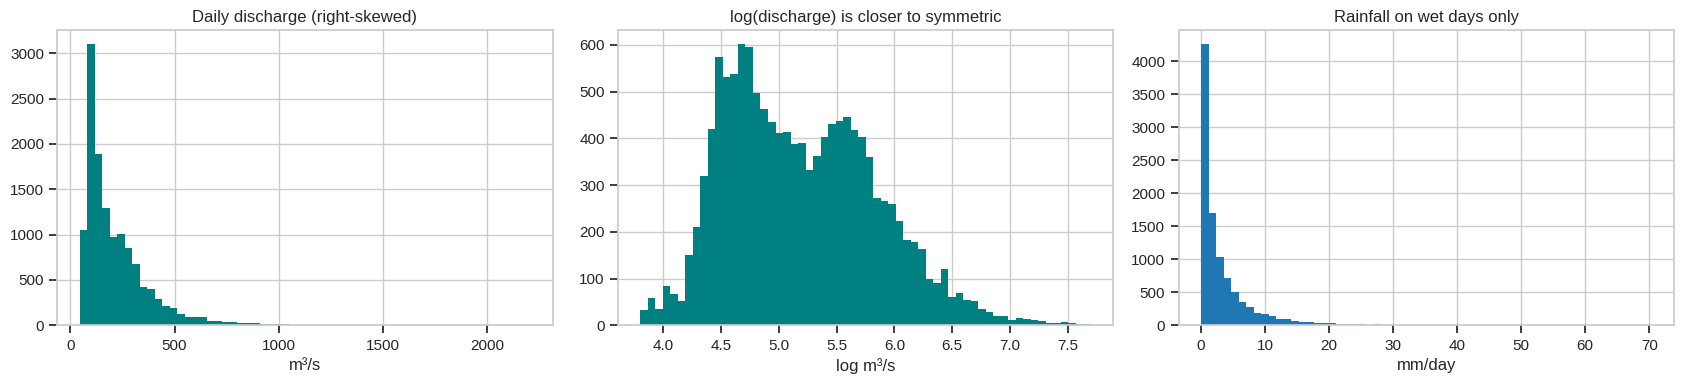

In [4]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4))
axes[0].hist(daily["discharge_m3s"], bins=60, color=COLORS["discharge_m3s"])
axes[0].set(title="Daily discharge (right-skewed)", xlabel="m³/s")
axes[1].hist(np.log(daily["discharge_m3s"]), bins=60, color=COLORS["discharge_m3s"])
axes[1].set(title="log(discharge) is closer to symmetric", xlabel="log m³/s")
axes[2].hist(daily.loc[daily["rainfall_mm"] > 0, "rainfall_mm"], bins=60, color=COLORS["rainfall_mm"])
axes[2].set(title="Rainfall on wet days only", xlabel="mm/day")
plt.tight_layout(); save_fig("01_distributions"); plt.show()

## 2 · Aggregate to monthly and annual scales
Rainfall is a *flux accumulated over time*, so it is **summed**; discharge, temperature and soil moisture are *states*, so they are **averaged**.
Getting this wrong (e.g. averaging rainfall) is a common mistake that silently changes every downstream conclusion.

In [5]:
monthly = kd.aggregate(daily, "MS")
annual  = kd.aggregate(daily, "YS")
monthly["month"] = monthly.index.month
print(f"Monthly records: {len(monthly)} | Annual records: {len(annual)}")
annual.round(1).head()

Monthly records: 432 | Annual records: 36


,rainfall_mm,discharge_m3s,temperature_c,soil_moisture_kgm2
date,,,,
1980-01-01,873.7,245.6,24.2,13.2
1981-01-01,1074.6,305.8,23.9,16.3
1982-01-01,691.4,201.4,24.2,14.0
1983-01-01,946.6,216.9,24.4,16.1
1984-01-01,888.4,231.0,23.9,18.5


## 3 · The 36-year picture

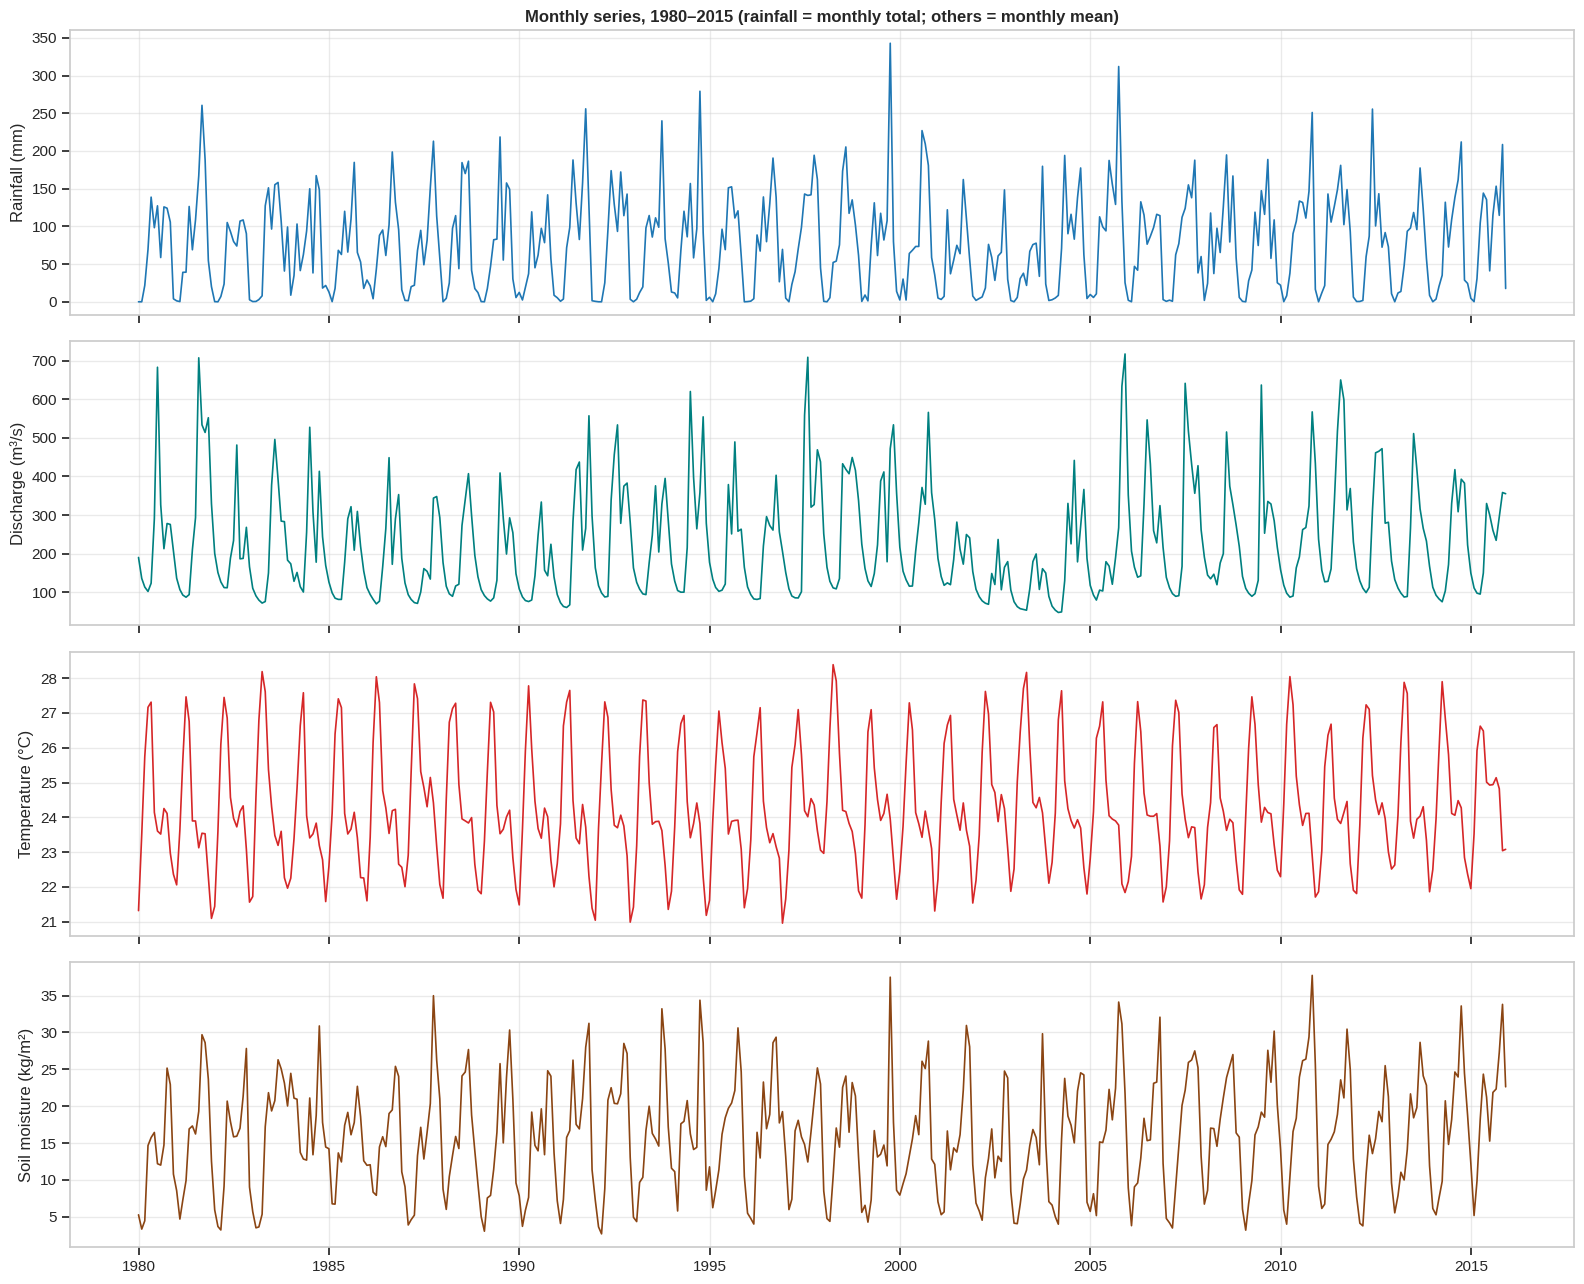

In [6]:
fig, axes = plt.subplots(4, 1, figsize=(16, 13), sharex=True)
for ax, p in zip(axes, kd.PARAMS):
    ax.plot(monthly.index, monthly[p], color=COLORS[p], lw=1.2)
    ax.set_ylabel(kd.LABELS[p]); ax.grid(alpha=.4)
axes[0].set_title("Monthly series, 1980–2015 (rainfall = monthly total; others = monthly mean)", fontweight="bold")
axes[-1].xaxis.set_major_locator(mdates.YearLocator(5))
axes[-1].xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
plt.tight_layout(); save_fig("01_monthly_timeseries"); plt.show()

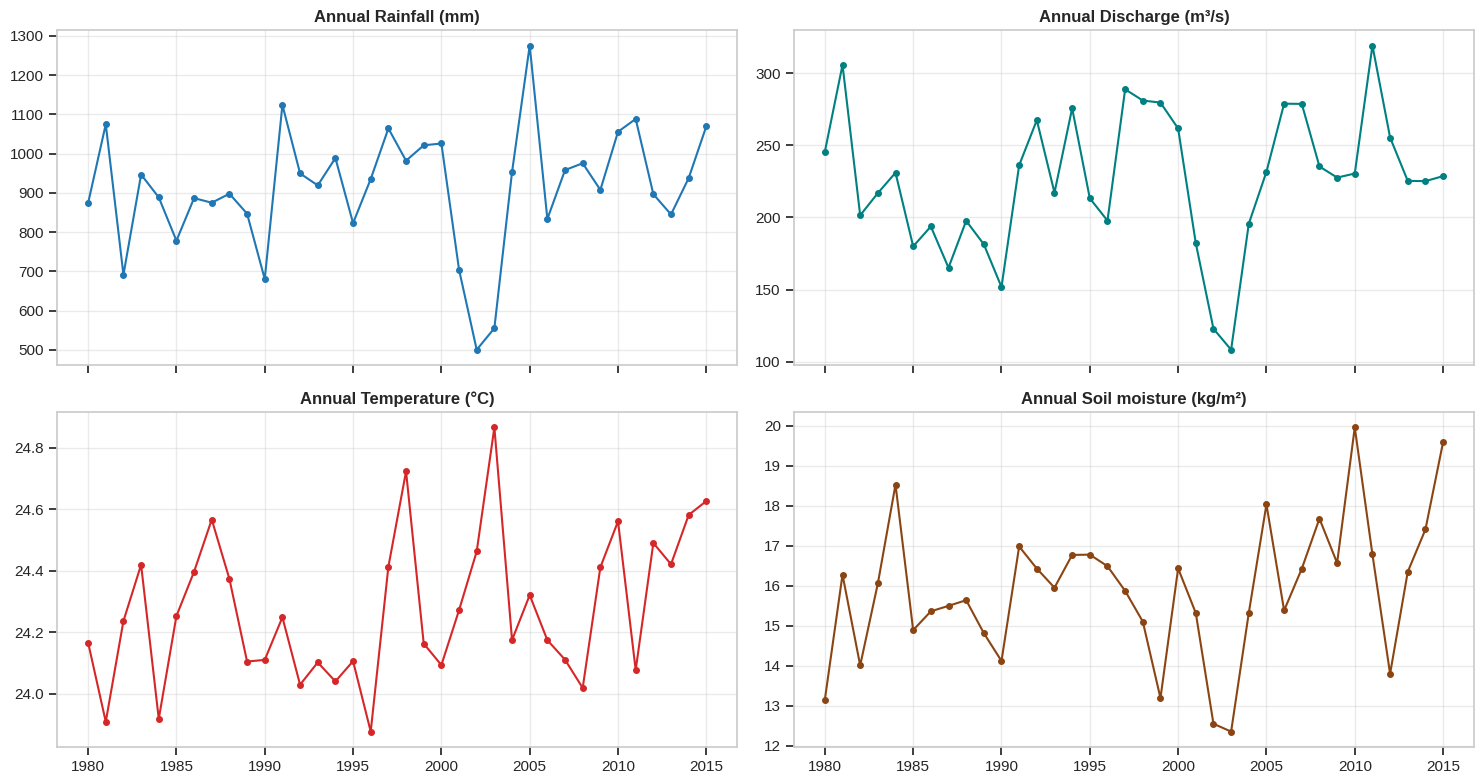

In [7]:
fig, axes = plt.subplots(2, 2, figsize=(15, 8), sharex=True)
for ax, p in zip(axes.ravel(), kd.PARAMS):
    ax.plot(annual.index.year, annual[p], marker="o", ms=4, color=COLORS[p])
    ax.set_title(f"Annual {kd.LABELS[p]}", fontweight="bold"); ax.grid(alpha=.4)
plt.tight_layout(); save_fig("01_annual_timeseries"); plt.show()

## 4 · Seasonality: what does a "typical year" look like?
Averaging all Januaries, all Februaries, … gives the **monthly climatology**. The shaded band shows the 25th–75th percentile across the 36 years,
so we see not only the typical value but also how variable each month is.

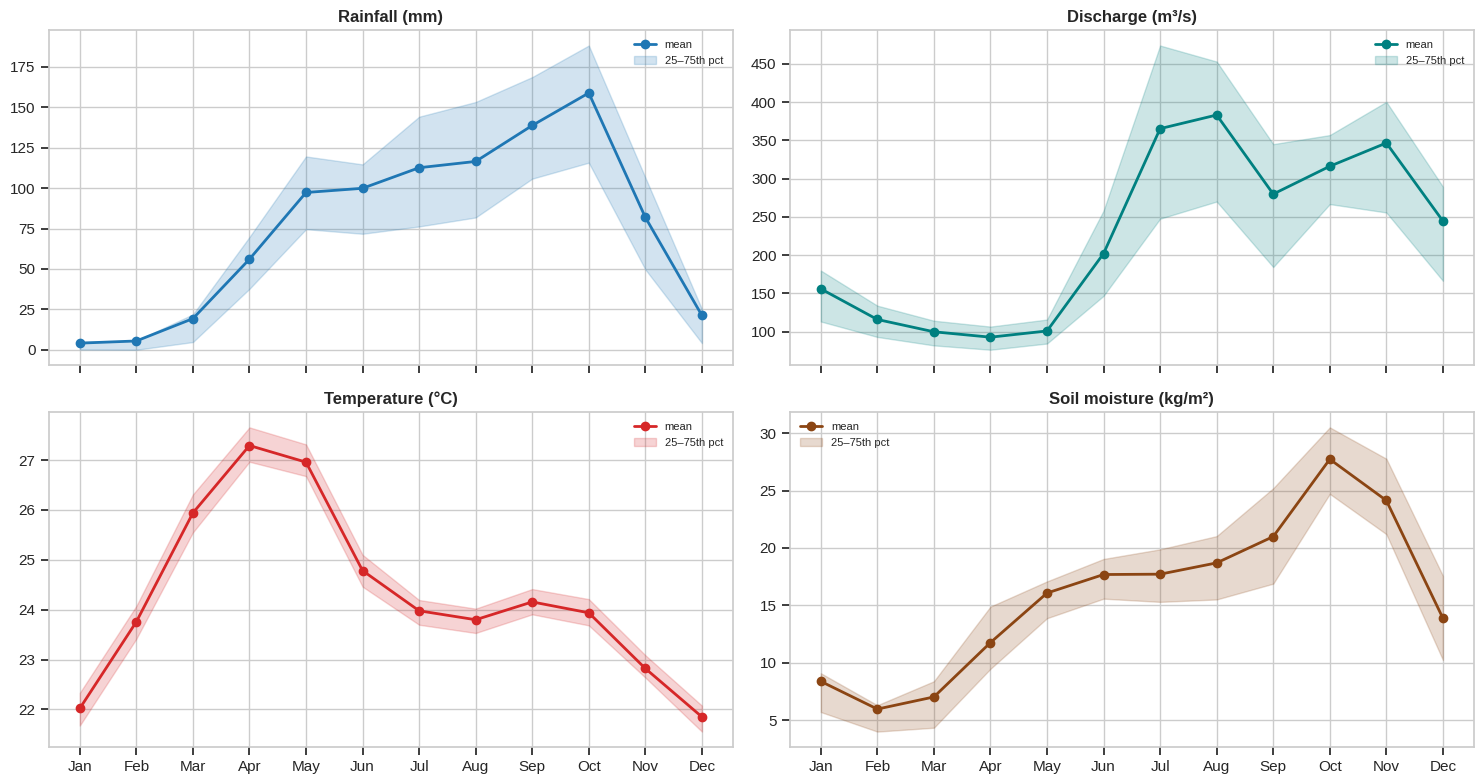

In [8]:
fig, axes = plt.subplots(2, 2, figsize=(15, 8), sharex=True)
months = ["Jan","Feb","Mar","Apr","May","Jun","Jul","Aug","Sep","Oct","Nov","Dec"]
for ax, p in zip(axes.ravel(), kd.PARAMS):
    g = monthly.groupby("month")[p]
    ax.plot(range(1, 13), g.mean(), marker="o", color=COLORS[p], lw=2, label="mean")
    ax.fill_between(range(1, 13), g.quantile(.25), g.quantile(.75), color=COLORS[p], alpha=.2, label="25–75th pct")
    ax.set_title(kd.LABELS[p], fontweight="bold"); ax.set_xticks(range(1, 13)); ax.set_xticklabels(months)
    ax.legend(fontsize=8)
plt.tight_layout(); save_fig("01_climatology"); plt.show()

In [9]:
clim = monthly.groupby("month")[kd.PARAMS].mean()
clim.index = months
clim.round(1)

,rainfall_mm,discharge_m3s,temperature_c,soil_moisture_kgm2
Jan,4.2,155.8,22.0,8.4
Feb,5.5,115.8,23.8,6.0
Mar,19.4,99.7,25.9,7.0
Apr,56.1,92.6,27.3,11.8
May,97.3,100.8,27.0,16.1
Jun,99.8,202.0,24.8,17.7
Jul,112.5,365.3,24.0,17.7
Aug,116.4,383.2,23.8,18.7
Sep,138.6,279.8,24.2,21.0
Oct,158.7,316.1,23.9,27.7


## 5 · Flow-duration curve: how often is the river this high?
A *flow-duration curve* (FDC) ranks all daily flows from highest to lowest. It is a standard hydrology KPI:
**Q10** = flow exceeded only 10 % of the time (high flows), **Q50** = median, **Q90** = flow exceeded 90 % of the time (low/dry-season flow).

{'Q10': 428.2, 'Q50': 166.6, 'Q90': 84.5}
Q10/Q90 ratio (flow variability): 5.1


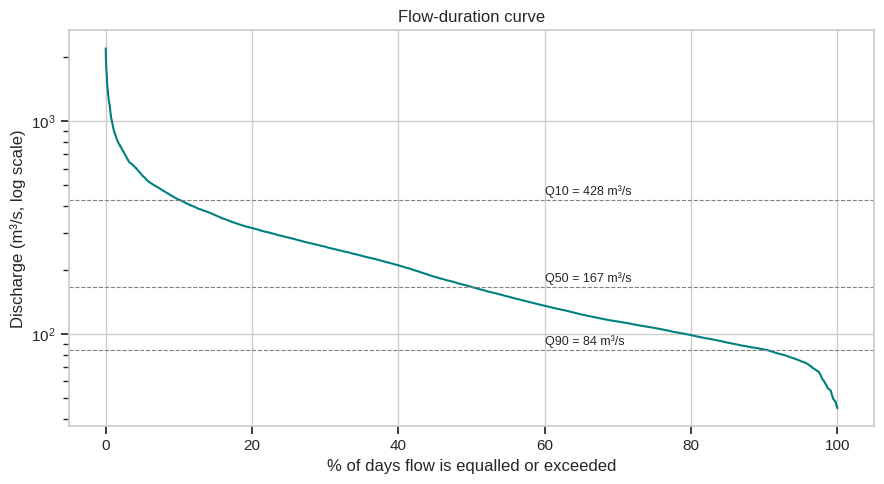

In [10]:
q = daily["discharge_m3s"].sort_values(ascending=False).reset_index(drop=True)
exceed = (np.arange(1, len(q) + 1) / len(q)) * 100
fdc = {f"Q{k}": float(np.percentile(daily["discharge_m3s"], 100 - k)) for k in (10, 50, 90)}

fig, ax = plt.subplots(figsize=(9, 5))
ax.plot(exceed, q, color=COLORS["discharge_m3s"]); ax.set_yscale("log")
for k, v in fdc.items():
    ax.axhline(v, ls="--", lw=.8, color="grey"); ax.text(60, v * 1.05, f"{k} = {v:,.0f} m³/s", fontsize=9)
ax.set(xlabel="% of days flow is equalled or exceeded", ylabel="Discharge (m³/s, log scale)", title="Flow-duration curve")
plt.tight_layout(); save_fig("01_flow_duration_curve"); plt.show()
print({k: round(v, 1) for k, v in fdc.items()})
print("Q10/Q90 ratio (flow variability):", round(fdc["Q10"] / fdc["Q90"], 1))

In [11]:
top = daily["discharge_m3s"].nlargest(5).to_frame("discharge_m3s")
top["year"] = top.index.year
annual_max = daily["discharge_m3s"].resample("YS").max()
print("Largest single-day flows:"); print(top.to_string())
print(f"Median annual-maximum flow: {annual_max.median():,.0f} m³/s | largest: {annual_max.max():,.0f} m³/s in {annual_max.idxmax().year}")

Largest single-day flows:
            discharge_m3s  year
date                           
1980-07-07         2208.0  1980
1981-08-21         2118.1  1981
2005-11-29         2097.0  2005
1980-07-06         2058.7  1980
1997-08-11         1998.7  1997
Median annual-maximum flow: 1,203 m³/s | largest: 2,208 m³/s in 1980


## 6 · Relationships between variables

### 6.1 Plain correlation and why monthly numbers can mislead
Because *every* variable follows the same yearly cycle, raw monthly correlations partly reflect **shared seasonality** rather than a direct link.
To separate the two we also correlate **anomalies** (value minus that calendar month's long-term mean).

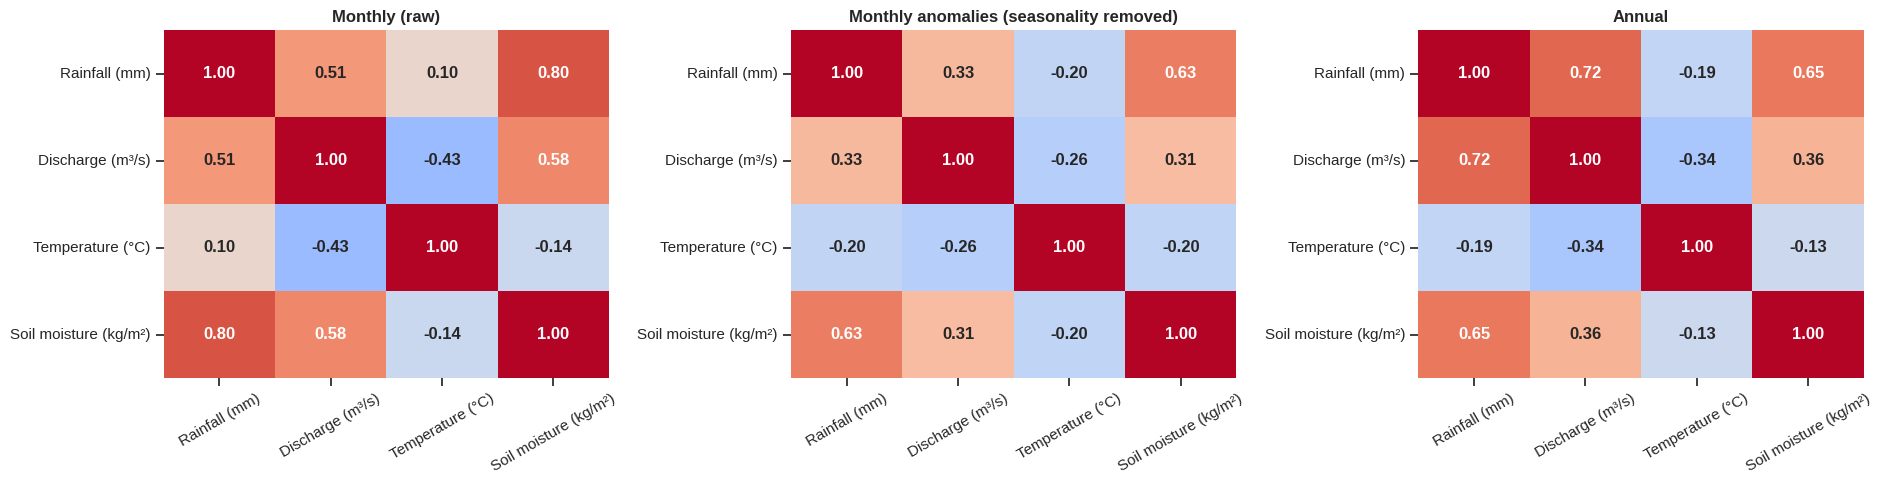

In [12]:
anom = monthly[kd.PARAMS] - monthly.groupby("month")[kd.PARAMS].transform("mean")

fig, axes = plt.subplots(1, 3, figsize=(19, 5))
for ax, (title, data) in zip(axes, [("Monthly (raw)", monthly[kd.PARAMS]),
                                    ("Monthly anomalies (seasonality removed)", anom),
                                    ("Annual", annual[kd.PARAMS])]):
    sns.heatmap(data.rename(columns=kd.LABELS).corr(), annot=True, fmt=".2f", cmap="coolwarm",
                vmin=-1, vmax=1, ax=ax, cbar=False, annot_kws={"weight": "bold"})
    ax.set_title(title, fontweight="bold"); ax.tick_params(axis="x", rotation=30)
plt.tight_layout(); save_fig("01_correlations"); plt.show()

### 6.2 Rainfall does not hit the river instantly - the lag structure
If discharge responds to rainfall with a delay (travel time, soil storage, reservoir operations), correlating rainfall in month *t* with discharge in month *t + k* should peak at some *k > 0*.

Monthly raw     : {0: 0.507, 1: 0.709, 2: 0.614, 3: 0.366, 4: 0.065}
Monthly anomaly : {0: 0.328, 1: 0.472, 2: 0.32, 3: 0.193, 4: 0.128}
Daily (7d rain) : {0: 0.389, 1: 0.42, 2: 0.442, 3: 0.453, 5: 0.435, 7: 0.412, 10: 0.413, 15: 0.418, 20: 0.404, 30: 0.351, 45: 0.363, 60: 0.349}


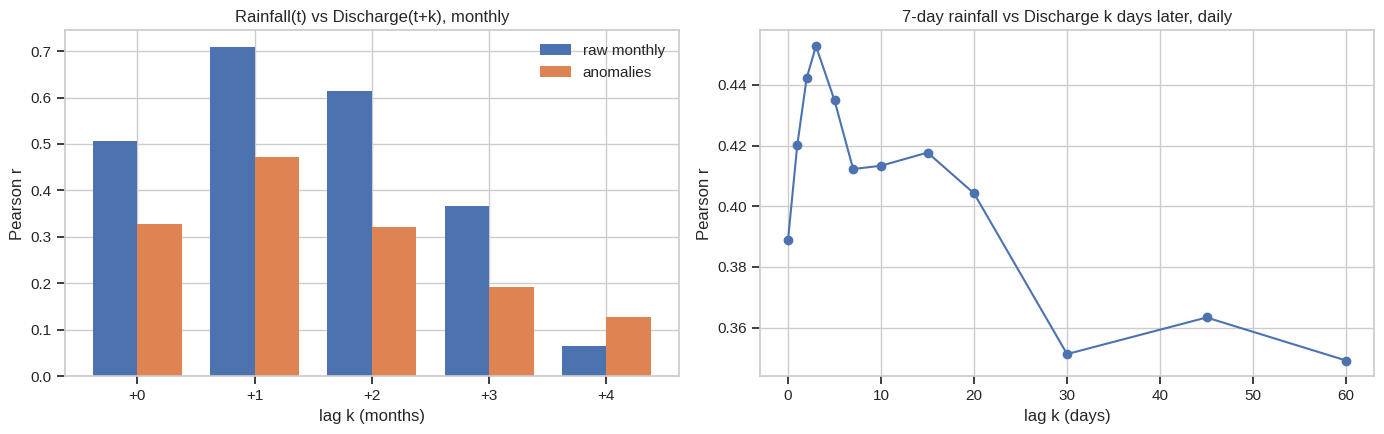

In [13]:
lags = range(0, 5)
monthly_lag = {k: monthly["rainfall_mm"].corr(monthly["discharge_m3s"].shift(-k)) for k in lags}
anom_lag    = {k: anom["rainfall_mm"].corr(anom["discharge_m3s"].shift(-k)) for k in lags}

# Daily view: 7-day rainfall total vs. discharge k days later
r7 = daily["rainfall_mm"].rolling(7).sum()
daily_lags = [0, 1, 2, 3, 5, 7, 10, 15, 20, 30, 45, 60]
daily_lag = {k: r7.corr(daily["discharge_m3s"].shift(-k)) for k in daily_lags}

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
x = np.arange(len(lags)); w = .38
axes[0].bar(x - w/2, list(monthly_lag.values()), w, label="raw monthly", color="#4c72b0")
axes[0].bar(x + w/2, list(anom_lag.values()), w, label="anomalies", color="#dd8452")
axes[0].set_xticks(x); axes[0].set_xticklabels([f"+{k}" for k in lags]); axes[0].legend()
axes[0].set(title="Rainfall(t) vs Discharge(t+k), monthly", xlabel="lag k (months)", ylabel="Pearson r")
axes[1].plot(daily_lags, list(daily_lag.values()), marker="o", color="#4c72b0")
axes[1].set(title="7-day rainfall vs Discharge k days later, daily", xlabel="lag k (days)", ylabel="Pearson r")
plt.tight_layout(); save_fig("01_lag_structure"); plt.show()
print("Monthly raw     :", {k: round(float(v), 3) for k, v in monthly_lag.items()})
print("Monthly anomaly :", {k: round(float(v), 3) for k, v in anom_lag.items()})
print("Daily (7d rain) :", {k: round(float(v), 3) for k, v in daily_lag.items()})

## 6.3 Key findings from the EDA
1. **Clean, complete data.** 13,149 consecutive daily records, no gaps, no negative values. Rainfall is zero on ~24.5 % of days; rainfall (skew 3.5) and discharge (skew 3.1) are strongly right-skewed.
2. **Discharge is bimodal through the year.** Mean monthly discharge peaks in **Jul–Aug (≈365–383 m³/s)** and again in **Oct–Nov (≈316–347 m³/s)**, with a clear low in **April (≈93 m³/s)**. This is consistent with the two Indian monsoon seasons feeding the Cauvery basin (south-west monsoon, then north-east monsoon) — an interpretation that should be checked against basin literature rather than taken from this data alone.
3. **Discharge rises *before* rainfall peaks.** Mean rainfall peaks in October (≈159 mm) but discharge is already high in Jul–Aug. Rainfall in this catchment is therefore not the only driver of flow — upstream rainfall and possibly reservoir releases (not in the dataset) matter. *This is a hypothesis, not something the data proves.*
4. **Flow variability is high.** Q10 ≈ 428 m³/s, Q50 ≈ 167 m³/s, Q90 ≈ 85 m³/s → the high-flow level is about **5×** the dry-season level. The largest daily flow was 2,208 m³/s on 7 Jul 1980; the median annual maximum is ≈ 1,203 m³/s.
5. **Rainfall → discharge has a lag.** Monthly rainfall correlates with *same-month* discharge at r = 0.51 but with *next-month* discharge at **r = 0.71** (anomalies: 0.33 → 0.47). The daily relationship is weak overall (r ≈ 0.39–0.45, peaking at a lag of ~3 days). → *Lagged rainfall must be a model feature* (used in notebooks 02 and 04).
6. **Part of every monthly correlation is just shared seasonality.** For example rainfall–discharge falls from r = 0.51 (raw) to 0.33 (anomalies); rainfall–soil-moisture from 0.80 to 0.63. Temperature is *negatively* related to discharge (r = −0.43 raw, −0.26 anomalies) — hot months are dry months, so this is association, not causation.

## 7 · Save the monthly table for later notebooks
Notebooks 02–04 recompute everything from the CSV through `kodumudi`, so nothing needs saving. The figures above were written to `reports/figures/` for the README and dashboard.

➡️ Next: **`02_statistical_analysis.ipynb`** - regression with robust standard errors and trend tests.